# Section 0: Setup

In [ ]:
!pip -q install torch scipy pandas pillow numpy

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d

Image.MAX_IMAGE_PIXELS = None

# Section 1: Pre-process Scan

In [ ]:
ROOT = Path('/content/drive/MyDrive/HTB2026')
STEM = '60808400140000_hadrian 2_masterlog_2in_10000-21962'
IMAGE_PATH = ROOT / 'dataset' / 'images' / f'{STEM}.tif'
ANNOTATION_PATH = ROOT / 'dataset' / 'bbox_annotation' / f'{STEM}.json'
LABEL_PATH = ROOT / 'test' / f'{STEM}.json'

WINDOW = 12
MIN_GAP = 6
INK_K = 6.0
PSEUDO_K = 10.0
CNN_THRESH = 0.5
TRAIN_PAGES = []
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

In [ ]:
# Crop a region of a very tall 1-bit or colour scan as RGB without decoding the whole page
def crop_rgb(img, box, scale=1.0, strip=2000):
    x0, y0, x1, y1 = box
    out = Image.new('RGB', (round((x1 - x0) * scale), round((y1 - y0) * scale)))
    for ys in range(y0, y1, strip):
        ye = min(ys + strip, y1)
        part = img.crop((x0, ys, x1, ye)).convert('RGB')
        top, bottom = round((ys - y0) * scale), round((ye - y0) * scale)
        if scale != 1.0:
            part = part.resize((out.width, max(1, bottom - top)), Image.Resampling.BOX)
        out.paste(part, (0, top))
    return out

In [ ]:
# Open the image and its annotation, and print the bounding boxes
image = Image.open(IMAGE_PATH)
annotation = json.loads(ANNOTATION_PATH.read_text())
boxes = annotation['bounding_boxes']

assert (annotation['width'], annotation['height']) == image.size
print('size:', image.size, 'mode:', image.mode)
for name, (x0, y0, x1, y1) in boxes.items():
    print(f'{name:30s} x {x0:5d}-{x1:5d}   y {y0:6d}-{y1:6d}')

size: (1700, 50000) mode: RGB
depth_column                   x   369-  449   y   1528- 49449
interpreted_lithology_column   x   525-  582   y   1528- 49449
lithology_legend               x     3- 1653   y    840-  1133


In [ ]:
# Load the interpreted lithology column as an RGB array and remember its y offset in the full image
def load_column(image_path, annotation_path):
    img = Image.open(image_path)
    ann = json.loads(Path(annotation_path).read_text())
    x0, y0, x1, y1 = ann['bounding_boxes']['interpreted_lithology_column']
    return np.array(crop_rgb(img, (x0, y0, x1, y1))), y0

col, y0 = load_column(IMAGE_PATH, ANNOTATION_PATH)
print('column array:', col.shape, 'y offset:', y0)

column array: (47921, 57, 3) y offset: 1528


# Section 2: Segment Lithology Columns

Split each interpreted lithology column into predicted segments.

- **Bed**: the interval between two detected boundaries (`y_top`, `y_bottom`).
- **Segment**: a cluster of consecutive beds belonging to the same lithology (e.g. one clay unit). Producing segments is called *clustering* or *segmentation*.

Naming segments from the legend is handled in a later section.

## 2.1 Row Features

In [37]:
# Trim the thick border lines on either side of the column
def trim_borders(col):
    dark = col.mean(2, dtype=np.float32) < 100
    profile = dark.mean(0)
    idx = np.where(profile > 0.6)[0]
    mid = col.shape[1] // 2
    left, right = idx[idx < mid], idx[idx >= mid]
    x0 = left.max() + 3 if left.size else 0
    x1 = right.min() - 2 if right.size else col.shape[1]
    return col if x1 - x0 < 10 else col[:, x0:x1]

FEATURE_NAMES = ['r', 'g', 'b', 'ink', 'htr', 'vtr']

# Raw per-row features: R, G, B means, ink density, horizontal and vertical stroke transitions
def raw_row_features(col, chunk=5000):
    col = trim_borders(col)
    feats, prev = [], None
    for s in range(0, len(col), chunk):
        part = col[s:s + chunk]
        dark = part.mean(2, dtype=np.float32) < 128
        rgb = part.mean(1, dtype=np.float32) / 255.0
        ink = dark.mean(1)
        htr = (dark[:, 1:] != dark[:, :-1]).mean(1)
        full = np.vstack([dark[:1] if prev is None else prev, dark])
        vtr = (full[1:] != full[:-1]).mean(1)
        feats.append(np.column_stack([rgb, ink, htr, vtr]))
        prev = dark[-1:]
    return np.vstack(feats).astype(np.float32)

# Same features, z-scored over the column (input to both boundary detectors)
def row_features(col, chunk=5000):
    F = raw_row_features(col, chunk)
    scale = F.std(0)
    scale[scale < 1e-6] = 1.0
    return (F - F.mean(0)) / scale

# Turn boundary rows into a table of bed tops and bottoms in full-image coordinates
def to_table(peaks, n, y_offset):
    edges = np.concatenate([[0], np.sort(peaks), [n]]).astype(int)
    return pd.DataFrame({'y_top': edges[:-1] + y_offset, 'y_bottom': edges[1:] + y_offset})

In [ ]:
# Compute the features once for the column loaded in Section 1
F = row_features(col)
print('feature matrix:', F.shape)

feature matrix: (47921, 6)


## 2.2 Ink Density

In [31]:
# Score each row by how much the average features change between the windows above and below it
def boundary_score(F, w=WINDOW):
    c = np.vstack([np.zeros((1, F.shape[1])), np.cumsum(F, 0)])
    n = len(F)
    ys = np.arange(w, n - w)
    above = (c[ys] - c[ys - w]) / w
    below = (c[ys + w] - c[ys]) / w
    score = np.zeros(n)
    score[ys] = np.linalg.norm(below - above, axis=1)
    return score

# Robust peak threshold: median + k * MAD, never below 1
def robust_threshold(s, k):
    med = np.median(s)
    mad = 1.4826 * np.median(np.abs(s - med))
    return max(med + k * max(mad, 1e-6), 1.0)

# Boundary rows from the ink-density method
def ink_boundaries(F, w=WINDOW, k=INK_K, gap=MIN_GAP):
    s = boundary_score(F, w)
    peaks, _ = find_peaks(s, height=robust_threshold(s, k), distance=gap)
    return peaks

In [ ]:
# Run the ink-density method and build the table of bed tops and bottoms
beds_ink = to_table(ink_boundaries(F), len(F), y0)
beds_ink

,y_top,y_bottom
0,1528,49449


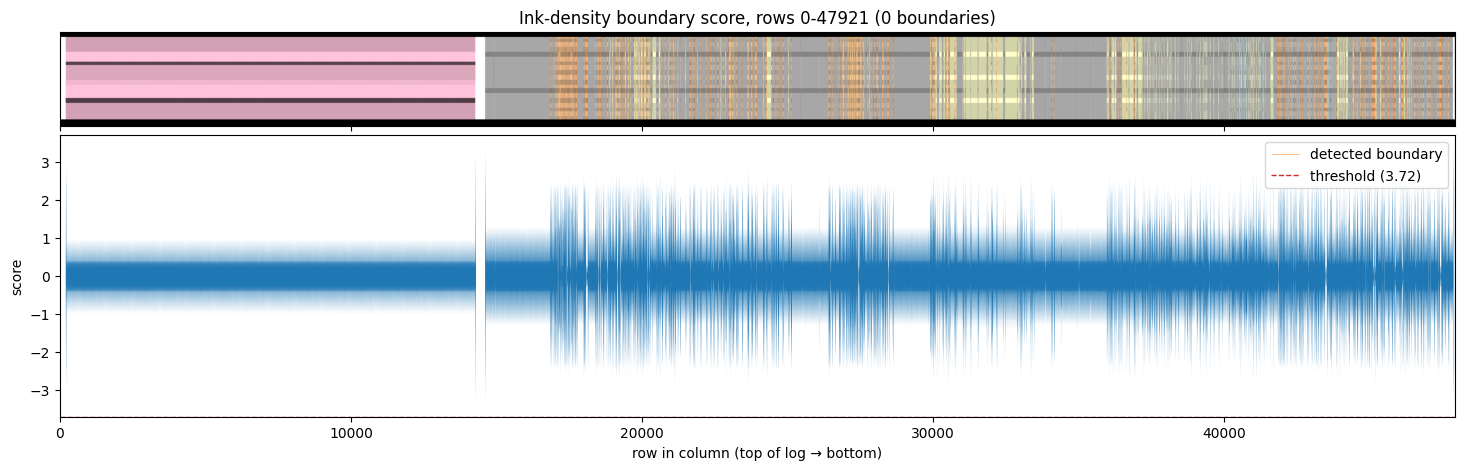

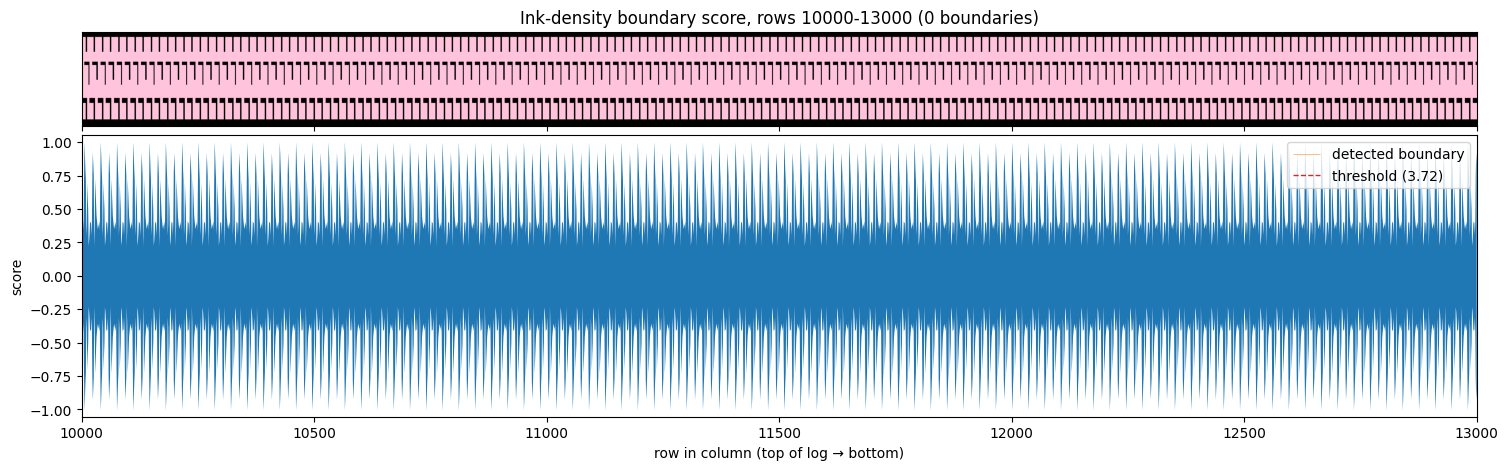

In [32]:
# Plot the ink-density boundary score as a mirrored waveform under the column scan
import matplotlib.pyplot as plt

def plot_ink_wave(col, F, start=0, length=None, w=WINDOW, k=INK_K):
    s = boundary_score(F, w)
    thr = robust_threshold(s, k)
    peaks = ink_boundaries(F, w, k)
    end = len(s) if length is None else min(start + length, len(s))
    ys = np.arange(start, end)
    seg = s[start:end]
    vis = peaks[(peaks >= start) & (peaks < end)]
    top = seg.max() * 1.05

    fig, (ax_img, ax) = plt.subplots(2, 1, figsize=(18, 5), sharex=True,
                                     gridspec_kw={'height_ratios': [1, 3], 'hspace': 0.05})
    ax_img.imshow(col[start:end].transpose(1, 0, 2), aspect='auto', extent=(start, end, 0, 1))
    ax_img.set_yticks([])
    ax_img.set_title(f'Ink-density boundary score, rows {start}-{end} ({len(vis)} boundaries)')
    ax.fill_between(ys, -seg, seg, color='tab:blue', lw=0)
    ax.vlines(vis, -top, top, color='tab:orange', lw=0.6, alpha=0.6, label='detected boundary')
    ax.axhline(thr, color='tab:red', ls='--', lw=1, label=f'threshold ({thr:.2f})')
    ax.axhline(-thr, color='tab:red', ls='--', lw=1)
    ax.set_ylim(-top, top)
    ax.set_xlim(start, end)
    ax.set_xlabel('row in column (top of log → bottom)')
    ax.set_ylabel('score')
    ax.legend(loc='upper right')
    plt.show()

# Whole column, then a zoomed-in stretch
plot_ink_wave(col, F)
plot_ink_wave(col, F, start=10000, length=3000)

## 2.3 Boundary CNN

In [33]:
# Small dilated 1D CNN that outputs a boundary probability for every row
N_FEATURES = 6
MODEL_PATH = ROOT / 'boundary_net.pt'

class BoundaryNet(nn.Module):
    def __init__(self, channels=N_FEATURES, hidden=32):
        super().__init__()
        layers, ch = [], channels
        for d in (1, 2, 4, 8, 16, 32):
            layers += [nn.Conv1d(ch, hidden, 3, padding=d, dilation=d), nn.ReLU()]
            ch = hidden
        layers.append(nn.Conv1d(hidden, 1, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)

# Soft target: a Gaussian bump around every pseudo-label boundary
def heatmap(n, peaks, sigma=1.5):
    h = np.zeros(n, np.float32)
    h[peaks] = 1.0
    h = gaussian_filter1d(h, sigma)
    return h / h.max() if h.max() > 0 else h

# Train on pseudo-labels (strong ink-density boundaries) from the given pages
def train_cnn(pages, steps=2000, length=1024, batch=16):
    assert pages, 'fill TRAIN_PAGES with (image_path, annotation_path) of train pages'
    data = []
    for img_path, ann_path in pages:
        c, _ = load_column(img_path, ann_path)
        f = row_features(c)
        data.append((f, heatmap(len(f), ink_boundaries(f, k=PSEUDO_K))))
    length = min(length, min(len(f) for f, _ in data))
    net = BoundaryNet(data[0][0].shape[1]).to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), 1e-3)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(20.0, device=DEVICE))
    rng = np.random.default_rng(0)
    for step in range(steps):
        xs, ys = [], []
        for _ in range(batch):
            f, h = data[rng.integers(len(data))]
            s = rng.integers(0, len(f) - length + 1)
            x, y = f[s:s + length], h[s:s + length]
            if rng.random() < 0.5:
                x, y = x[::-1], y[::-1]
            x = x * rng.uniform(0.8, 1.2, x.shape[1]) + rng.normal(0, 0.05, x.shape)
            xs.append(x.T.copy())
            ys.append(y.copy())
        xb = torch.tensor(np.stack(xs), dtype=torch.float32, device=DEVICE)
        yb = torch.tensor(np.stack(ys), dtype=torch.float32, device=DEVICE)
        loss = loss_fn(net(xb), yb)
        opt.zero_grad()
        loss.backward()
        opt.step()
        if step % 200 == 0:
            print(step, float(loss))
    return net

# Boundary probability for every row of a feature matrix
def cnn_probs(net, F):
    net.eval()
    with torch.no_grad():
        x = torch.tensor(F.T[None], dtype=torch.float32, device=DEVICE)
        return torch.sigmoid(net(x))[0].cpu().numpy()

# Boundary rows from the CNN
def cnn_boundaries(net, F, thresh=CNN_THRESH, gap=MIN_GAP):
    peaks, _ = find_peaks(cnn_probs(net, F), height=thresh, distance=gap)
    return peaks

In [34]:
# Build TRAIN_PAGES from the Drive dataset, excluding test, held-out and tiny pages
def clean(name):
    return name[:-4] if name.lower().endswith(('.tif', '.png')) else name

excluded = {p.stem for p in (ROOT / 'test').glob('*.json')}
allowed = None
if (ROOT / 'splits.json').exists():
    sp = json.loads((ROOT / 'splits.json').read_text())
    entry = lambda s: s['stem'] if isinstance(s, dict) else s
    excluded |= {clean(entry(s)) for s in sp['test']}
    allowed = {clean(entry(s)) for s in sp['train']}

TRAIN_PAGES = []
for ann_path in sorted((ROOT / 'dataset' / 'bbox_annotation').glob('*.json')):
    ann = json.loads(ann_path.read_text())
    stem = clean(ann['image_name'])
    img_path = ROOT / 'dataset' / 'images' / ann['image_name']
    x0, top, x1, bottom = ann['bounding_boxes']['interpreted_lithology_column']
    if not img_path.exists() or stem in excluded or stem.startswith('0000000009'):
        continue
    if allowed is not None and stem not in allowed:
        continue
    if bottom - top < 5000:
        continue
    TRAIN_PAGES.append((img_path, ann_path))

print(len(TRAIN_PAGES), 'train pages')

40 train pages


In [ ]:
# Train the CNN, save it to Drive, and build the table of bed tops and bottoms for the Section 1 column
net = train_cnn(TRAIN_PAGES)
torch.save(net.state_dict(), MODEL_PATH)
beds_cnn = to_table(cnn_boundaries(net, F), len(F), y0)
beds_cnn

## 2.4 Predict Beds

In [38]:
# Find a page's image and annotation on Drive from its stem
def page_paths(stem):
    ann_path = ROOT / 'dataset' / 'bbox_annotation' / f'{stem}.json'
    for ext in ('.tif', '.png'):
        img_path = ROOT / 'dataset' / 'images' / f'{stem}{ext}'
        if img_path.exists():
            return img_path, ann_path
    raise FileNotFoundError(f'no image for {stem}')

# Load the trained BoundaryNet saved by the training cell
def load_model(path=MODEL_PATH):
    net = BoundaryNet().to(DEVICE)
    net.load_state_dict(torch.load(path, map_location=DEVICE))
    return net.eval()

# Detect the beds of an already-loaded column
def beds_from_column(col, y_offset, net=None, method='cnn', thresh=CNN_THRESH):
    F = row_features(col)
    if method == 'ink':
        peaks = ink_boundaries(F)
    else:
        peaks = cnn_boundaries(net if net is not None else load_model(), F, thresh)
    return to_table(peaks, len(F), y_offset)

# Predict the beds of one page's lithology column; returns y_top / y_bottom in full-image pixels
def predict_beds(stem, net=None, method='cnn', thresh=CNN_THRESH):
    col, y_offset = load_column(*page_paths(stem))
    return beds_from_column(col, y_offset, net, method, thresh)

In [36]:
# Predict the beds of the test column from Section 1 (pass net=None to load the saved model instead)
beds_pred = predict_beds(STEM, net=net)
print(len(beds_pred), 'beds')
beds_pred

747 beds


,y_top,y_bottom
0,1528,1530
1,1530,1730
2,1730,15796
3,15796,16135
4,16135,16141
...,...,...
742,49246,49379
743,49379,49434
744,49434,49440
745,49440,49446


## 2.5 Clustering Beds into Segments

Group the beds from 2.4 into segments.

In [46]:
SEG_THRESH = 0.2   # merge neighbouring beds while their RMS feature distance (in column std units) is below this
MIN_BED_PX = 0     # beds thinner than this are first absorbed into their most similar neighbour (0 = off; real layers can be ~12-25 px)

# Merge beds into segments: absorb slivers, then repeatedly merge the most similar pair of neighbouring beds
def cluster_beds(beds, R, y_offset, thresh=SEG_THRESH, min_px=MIN_BED_PX):
    R = R.astype(np.float64)
    c1 = np.vstack([np.zeros((1, R.shape[1])), np.cumsum(R, 0)])
    c2 = np.vstack([np.zeros((1, R.shape[1])), np.cumsum(R ** 2, 0)])
    scale = R.std(0)
    scale[scale < 1e-6] = 1.0
    scale = np.concatenate([scale, scale])

    beds = beds[beds.y_bottom > beds.y_top]
    tops = list(beds.y_top - y_offset)
    bots = list(beds.y_bottom - y_offset)
    counts = [1] * len(tops)

    # Descriptor of segment k: mean and std of every raw feature over its rows
    def stats(k):
        t, b = tops[k], bots[k]
        mean = (c1[b] - c1[t]) / (b - t)
        std = np.sqrt(np.maximum((c2[b] - c2[t]) / (b - t) - mean ** 2, 0))
        return np.concatenate([mean, std])

    def dist(a, b):
        return float(np.sqrt(np.mean(((stats(a) - stats(b)) / scale) ** 2)))

    def merge(k):
        bots[k] = bots[k + 1]
        counts[k] += counts[k + 1]
        del tops[k + 1], bots[k + 1], counts[k + 1]

    while len(tops) > 1:
        h = np.array(bots) - np.array(tops)
        k = int(np.argmin(h))
        if h[k] >= min_px:
            break
        if k == 0:
            merge(0)
        elif k == len(tops) - 1:
            merge(k - 1)
        else:
            merge(k - 1 if dist(k - 1, k) <= dist(k, k + 1) else k)

    d = [dist(k, k + 1) for k in range(len(tops) - 1)]
    while d:
        k = int(np.argmin(d))
        if d[k] > thresh:
            break
        merge(k)
        del d[k]
        if k > 0:
            d[k - 1] = dist(k - 1, k)
        if k < len(d):
            d[k] = dist(k, k + 1)

    n = len(FEATURE_NAMES)
    rows = []
    for k in range(len(tops)):
        s = stats(k)
        rows.append({'segment': k, 'y_top': tops[k] + y_offset, 'y_bottom': bots[k] + y_offset,
                     'height': bots[k] - tops[k], 'n_beds': counts[k],
                     **{f'mean_{f}': v for f, v in zip(FEATURE_NAMES, s[:n])},
                     **{f'std_{f}': v for f, v in zip(FEATURE_NAMES, s[n:])}})
    return pd.DataFrame(rows)

In [47]:
# Cluster the beds predicted in 2.4 into segments
R = raw_row_features(col)
segments = cluster_beds(beds_pred, R, y0)
print(len(beds_pred), 'beds ->', len(segments), 'segments')
segments

747 beds -> 700 segments


,segment,y_top,y_bottom,height,n_beds,mean_r,mean_g,mean_b,mean_ink,mean_htr,mean_vtr,std_r,std_g,std_b,std_ink,std_htr,std_vtr
0,0,1528,1530,2,1,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,1,1530,1730,200,1,0.999022,0.995723,0.997042,0.000978,0.000667,0.005326,0.007927,0.034663,0.023969,0.007927,0.005402,0.070660
2,2,1730,15796,14066,1,0.839116,0.641677,0.720652,0.160884,0.059687,0.075776,0.143293,0.109577,0.123063,0.143293,0.021098,0.137036
3,3,15796,16135,339,1,0.996697,0.996169,0.996380,0.002437,0.000262,0.004168,0.040255,0.044315,0.042472,0.034337,0.003404,0.046732
4,4,16135,16141,6,1,0.720404,0.720404,0.720404,0.090580,0.007407,0.090580,0.160445,0.160445,0.160445,0.202542,0.016563,0.202542
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
695,695,49210,49236,26,1,0.842281,0.619346,0.422467,0.130435,0.083761,0.117057,0.151608,0.111924,0.141760,0.147319,0.088096,0.172557
696,696,49236,49379,143,2,0.638615,0.638615,0.638615,0.193828,0.015229,0.134691,0.212902,0.212902,0.212902,0.268763,0.021093,0.241397
697,697,49379,49440,61,2,0.989778,0.989778,0.989778,0.000000,0.000000,0.000000,0.044945,0.044945,0.044945,0.000000,0.000000,0.000000
698,698,49440,49446,6,1,0.500000,0.500000,0.500000,0.500000,0.000000,0.166667,0.500000,0.500000,0.500000,0.500000,0.000000,0.372678


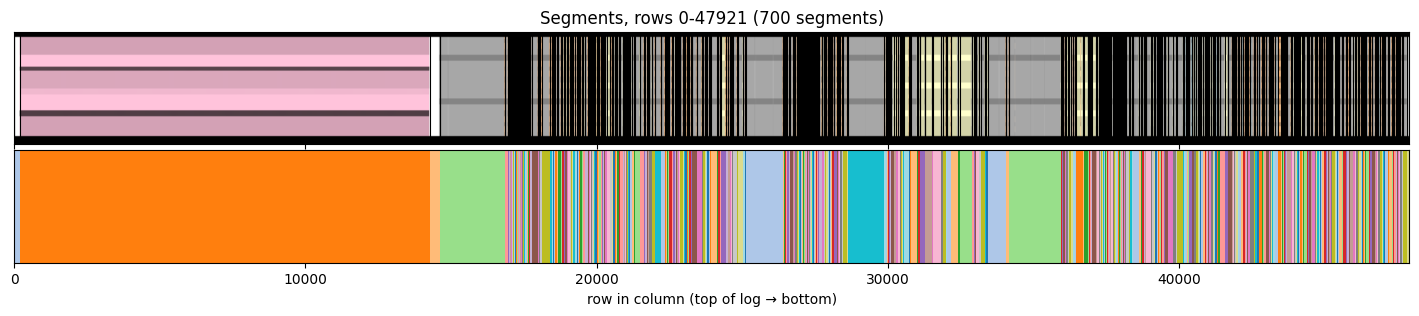

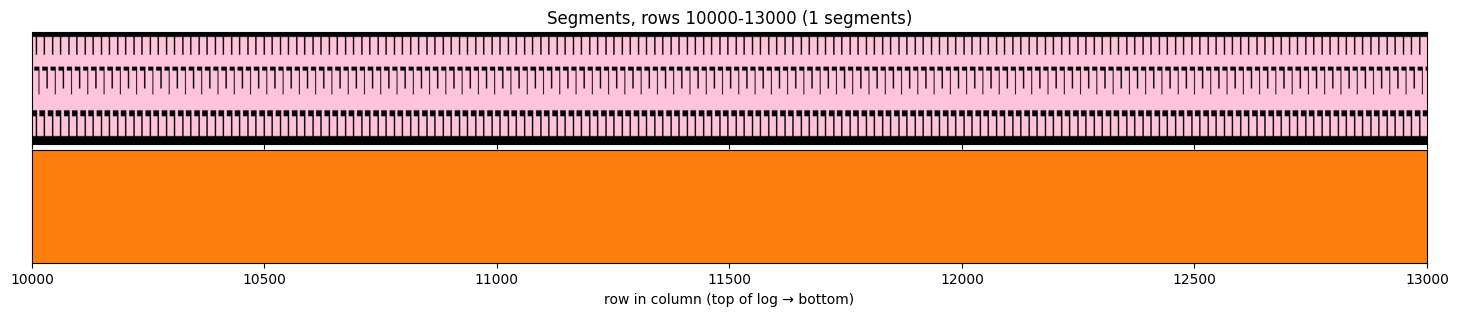

In [48]:
# Show the segments as coloured bands under the column scan
def plot_segments(col, segments, y_offset, start=0, length=None):
    end = len(col) if length is None else min(start + length, len(col))
    seg = segments[(segments.y_bottom - y_offset > start) & (segments.y_top - y_offset < end)]
    fig, (ax_img, ax) = plt.subplots(2, 1, figsize=(18, 3), sharex=True,
                                     gridspec_kw={'height_ratios': [1, 1], 'hspace': 0.05})
    ax_img.imshow(col[start:end].transpose(1, 0, 2), aspect='auto', extent=(start, end, 0, 1))
    ax_img.set_yticks([])
    ax_img.set_title(f'Segments, rows {start}-{end} ({len(seg)} segments)')
    colors = plt.cm.tab20.colors
    for s in seg.itertuples():
        a, b = s.y_top - y_offset, s.y_bottom - y_offset
        ax.axvspan(a, b, color=colors[s.segment % len(colors)], lw=0)
        ax_img.axvline(a, color='k', lw=0.8)
    ax.set_yticks([])
    ax.set_xlim(start, end)
    ax.set_xlabel('row in column (top of log → bottom)')
    plt.show()

# Whole column, then the same zoomed-in stretch as the ink-density plot
plot_segments(col, segments, y0)
plot_segments(col, segments, y0, start=10000, length=3000)

In [49]:
# Predict the segments of one page's lithology column: detect beds, then cluster them
def predict_segments(stem, net=None, method='cnn', thresh=SEG_THRESH, min_px=MIN_BED_PX):
    col, y_offset = load_column(*page_paths(stem))
    beds = beds_from_column(col, y_offset, net, method)
    return cluster_beds(beds, raw_row_features(col), y_offset, thresh, min_px)

In [50]:
# Predict the segments of the test column from Section 1 (pass net=None to load the saved model instead)
segments_pred = predict_segments(STEM, net=net)
print(len(segments_pred), 'segments')
segments_pred

700 segments


,segment,y_top,y_bottom,height,n_beds,mean_r,mean_g,mean_b,mean_ink,mean_htr,mean_vtr,std_r,std_g,std_b,std_ink,std_htr,std_vtr
0,0,1528,1530,2,1,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,1,1530,1730,200,1,0.999022,0.995723,0.997042,0.000978,0.000667,0.005326,0.007927,0.034663,0.023969,0.007927,0.005402,0.070660
2,2,1730,15796,14066,1,0.839116,0.641677,0.720652,0.160884,0.059687,0.075776,0.143293,0.109577,0.123063,0.143293,0.021098,0.137036
3,3,15796,16135,339,1,0.996697,0.996169,0.996380,0.002437,0.000262,0.004168,0.040255,0.044315,0.042472,0.034337,0.003404,0.046732
4,4,16135,16141,6,1,0.720404,0.720404,0.720404,0.090580,0.007407,0.090580,0.160445,0.160445,0.160445,0.202542,0.016563,0.202542
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
695,695,49210,49236,26,1,0.842281,0.619346,0.422467,0.130435,0.083761,0.117057,0.151608,0.111924,0.141760,0.147319,0.088096,0.172557
696,696,49236,49379,143,2,0.638615,0.638615,0.638615,0.193828,0.015229,0.134691,0.212902,0.212902,0.212902,0.268763,0.021093,0.241397
697,697,49379,49440,61,2,0.989778,0.989778,0.989778,0.000000,0.000000,0.000000,0.044945,0.044945,0.044945,0.000000,0.000000,0.000000
698,698,49440,49446,6,1,0.500000,0.500000,0.500000,0.500000,0.000000,0.166667,0.500000,0.500000,0.500000,0.500000,0.000000,0.372678


In [51]:
# Score predicted segments against the labelled test page: true segments are runs of consecutive layers with the same composition
def gt_segments(label_path):
    lab = json.loads(Path(label_path).read_text())
    rows = []
    for l in sorted(lab['layers'], key=lambda l: l['top_px']):
        key = tuple(sorted((p['legend_id'], round(p['proportion'], 2)) for p in l['composition']))
        if rows and rows[-1]['key'] == key and abs(rows[-1]['y_bottom'] - l['top_px']) <= 2:
            rows[-1]['y_bottom'] = l['bottom_px']
        else:
            rows.append({'y_top': l['top_px'], 'y_bottom': l['bottom_px'], 'key': key})
    return pd.DataFrame(rows).drop(columns='key')

# Boundary precision / recall / F1, where a boundary counts as matched within tol pixels
def boundary_f1(pred, gt, tol=10):
    p = np.unique(np.r_[pred.y_top, pred.y_bottom])
    g = np.unique(np.r_[gt.y_top, gt.y_bottom])
    prec = float(np.mean([np.abs(g - x).min() <= tol for x in p]))
    rec = float(np.mean([np.abs(p - x).min() <= tol for x in g]))
    return {'precision': round(prec, 3), 'recall': round(rec, 3), 'f1': round(2 * prec * rec / max(prec + rec, 1e-9), 3)}

gt = gt_segments(LABEL_PATH)
print(len(gt), 'true segments')
print('beds    ', len(beds_pred), boundary_f1(beds_pred, gt))
print('segments', len(segments_pred), boundary_f1(segments_pred, gt))

671 true segments
beds     747 {'precision': 0.972, 'recall': 0.951, 'f1': 0.962}
segments 700 {'precision': 0.983, 'recall': 0.947, 'f1': 0.965}


In [52]:
# Run segment predictions for one page and save them to Drive for evaluation elsewhere
PRED_STEM = '60808400140000_hadrian 2_masterlog_2in_10000-21962'
PRED_DIR = ROOT / 'predictions'
PRED_DIR.mkdir(parents=True, exist_ok=True)

pred = predict_segments(PRED_STEM, net=globals().get('net'))
img_path, _ = page_paths(PRED_STEM)

pred.to_csv(PRED_DIR / f'{PRED_STEM}.csv', index=False)
(PRED_DIR / f'{PRED_STEM}.json').write_text(json.dumps({
    'image_name': img_path.name,
    'method': 'cnn',
    'seg_thresh': SEG_THRESH,
    'min_bed_px': MIN_BED_PX,
    'layers': [{'top_px': int(r.y_top), 'bottom_px': int(r.y_bottom), 'n_beds': int(r.n_beds)}
               for r in pred.itertuples()],
}, indent=1))

print(len(pred), 'segments saved to', PRED_DIR)
for p in sorted(PRED_DIR.glob(f'{PRED_STEM}.*')):
    print(' ', p.name, p.stat().st_size, 'bytes')

700 segments saved to /content/drive/MyDrive/HTB2026/predictions
  60808400140000_hadrian 2_masterlog_2in_10000-21962.csv 178210 bytes
  60808400140000_hadrian 2_masterlog_2in_10000-21962.json 47042 bytes


## 2.6 Visual Check

Stretches of the column side by side: the original scan, predicted segment boundaries (red) and, for labelled pages, true segment boundaries (green).

In [53]:
# Boundaries of a segment table that fall inside rows [start, end) of the column
def boundaries_in(table, y_offset, start, end):
    ys = np.unique(np.r_[table.y_top, table.y_bottom]) - y_offset
    return ys[(ys > start) & (ys < end)]

# Show windows of a page as vertical strips: original, predicted boundaries, true boundaries (if labelled)
def compare_panels(stem, segments, starts=None, n=5, length=1500, label_path=None):
    col, y_offset = load_column(*page_paths(stem))
    label_path = Path(label_path) if label_path else ROOT / 'test' / f'{stem}.json'
    gt = gt_segments(label_path) if label_path.exists() else None
    if starts is None:
        starts = np.linspace(0, max(len(col) - length, 0), n).astype(int)

    views = [('original', None, None), ('predicted', segments, 'tab:red')]
    if gt is not None:
        views.append(('true', gt, 'tab:green'))
    fig, axes = plt.subplots(1, len(starts) * len(views), figsize=(1.6 * len(starts) * len(views), 12),
                             gridspec_kw={'wspace': 0.08})
    for j, start in enumerate(starts):
        end = min(start + length, len(col))
        for k, (name, table, color) in enumerate(views):
            ax = axes[j * len(views) + k]
            ax.imshow(col[start:end], aspect='auto', interpolation='nearest',
                      extent=(0, col.shape[1], end + y_offset, start + y_offset))
            if table is not None:
                ax.hlines(boundaries_in(table, y_offset, start, end) + y_offset, 0, col.shape[1], color=color, lw=1.2)
            ax.set_xticks([])
            ax.set_title(name, fontsize=9, color=color or 'black')
            if k:
                ax.set_yticks([])
            else:
                ax.set_ylabel('image y (px)')
    score = f' | boundary {boundary_f1(segments, gt)}' if gt is not None else ''
    fig.suptitle(f'{stem}: {len(segments)} predicted segments{score}', fontsize=11)
    plt.show()

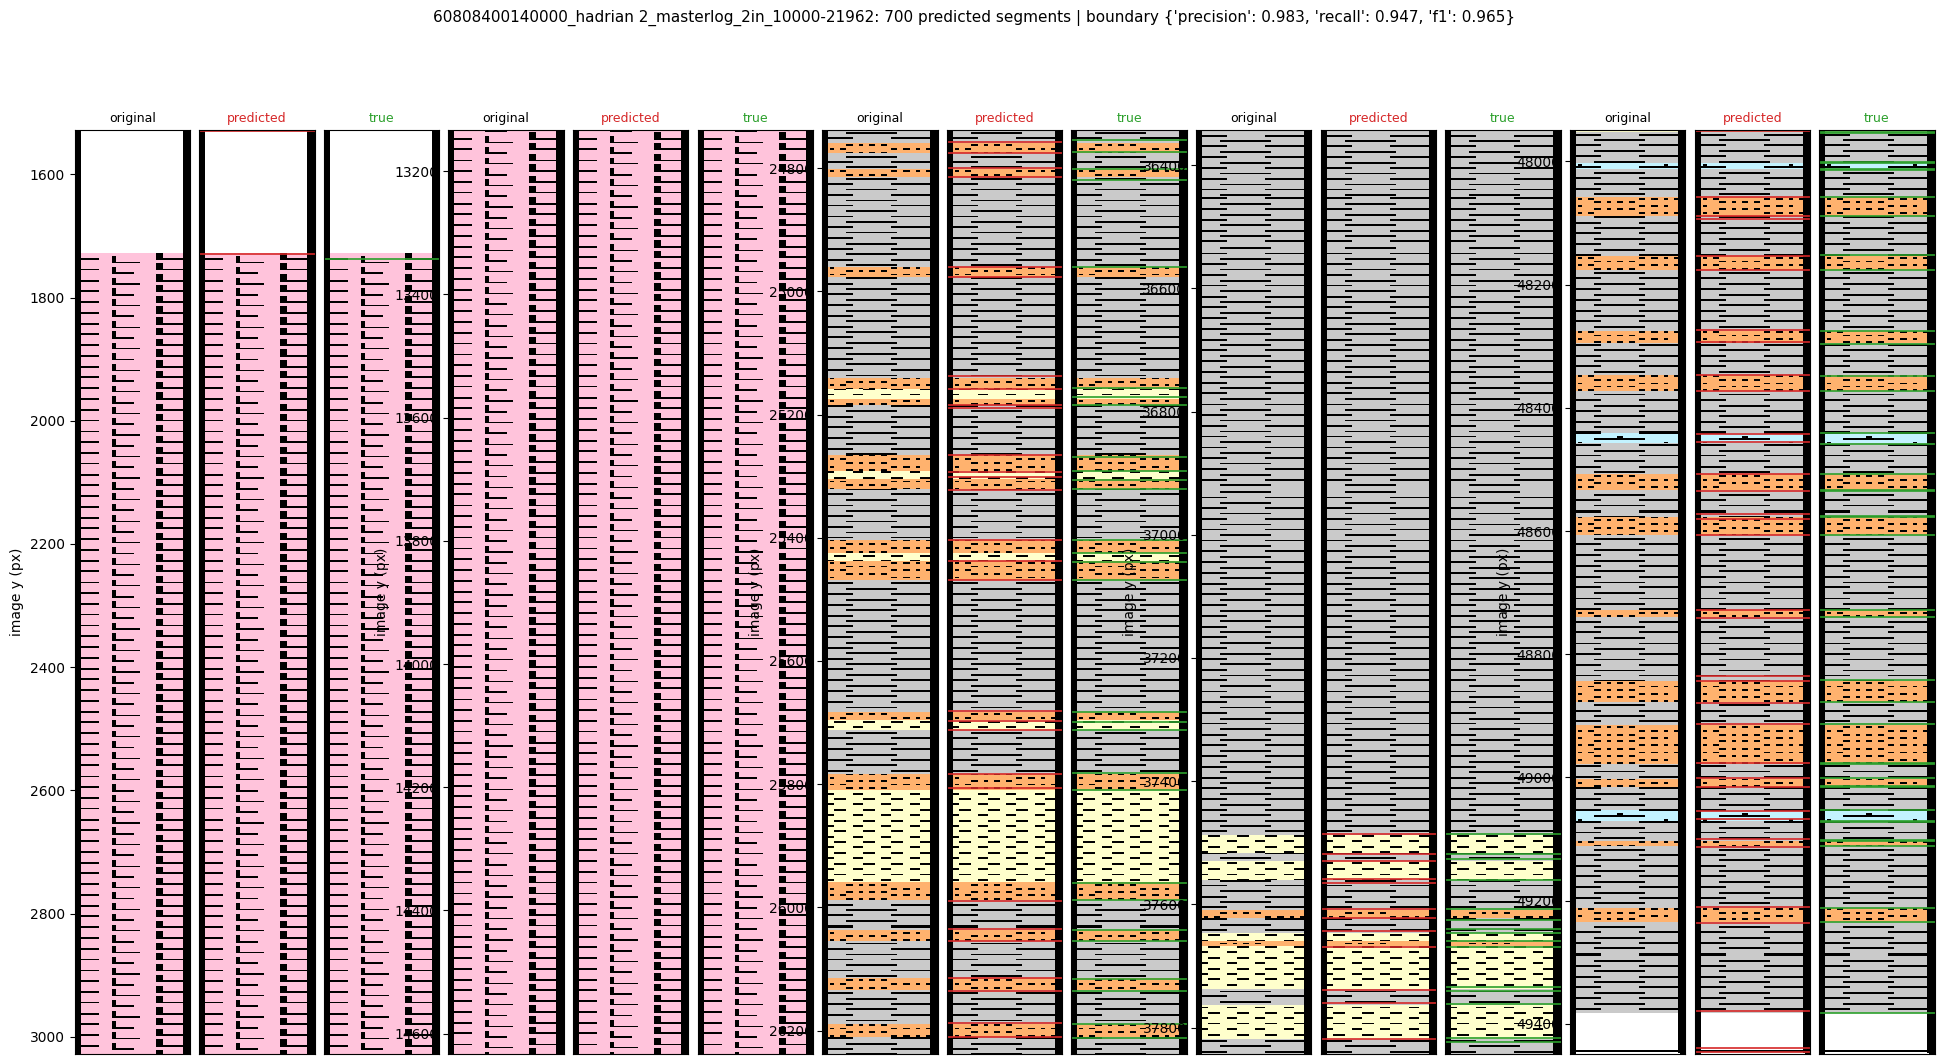

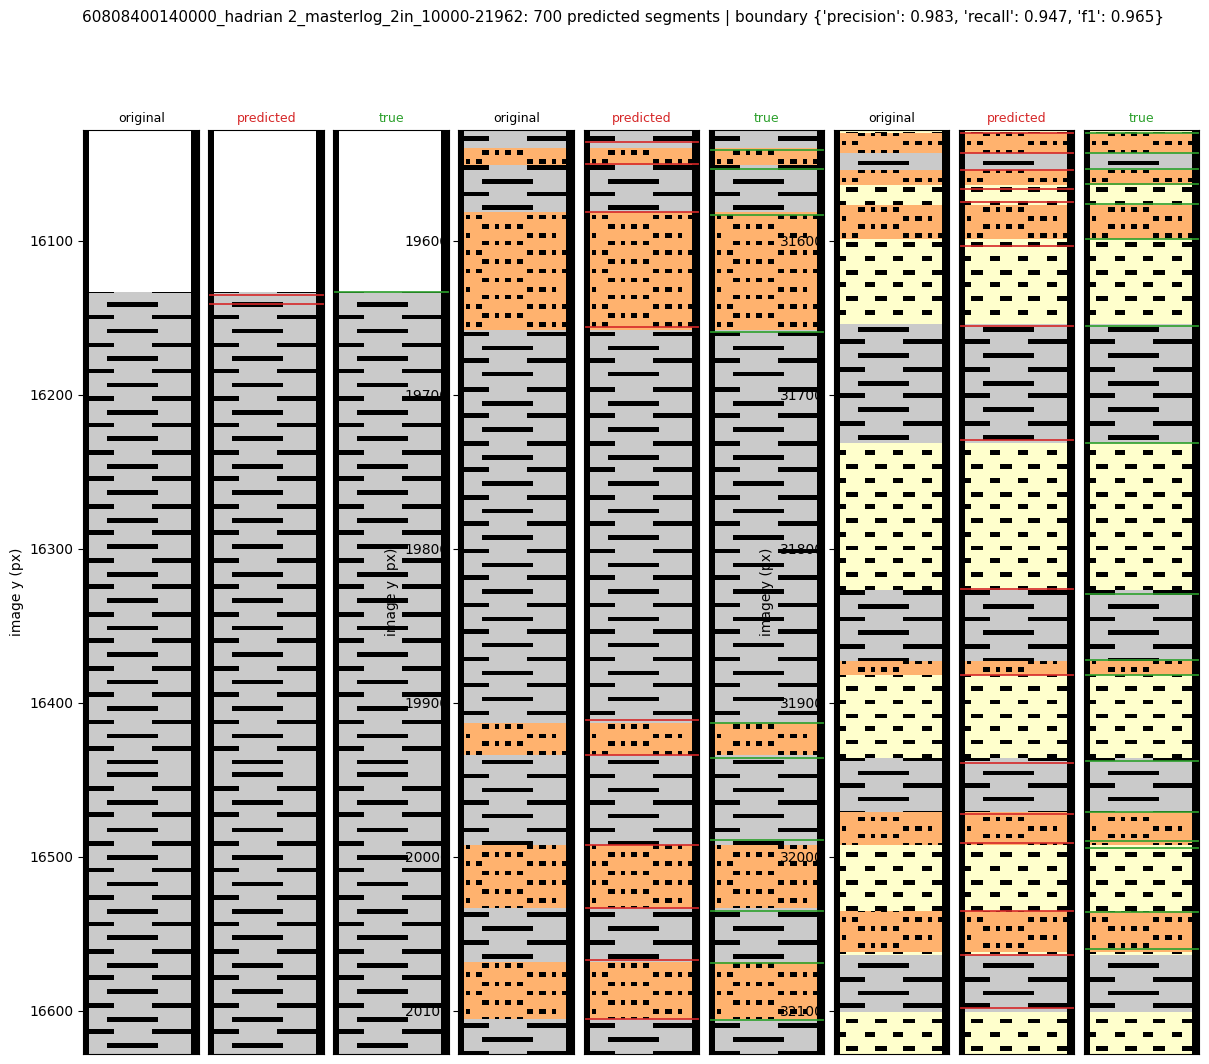

In [54]:
# Five evenly spaced windows of the test page; pass starts=[...] (column rows) to look at specific stretches
compare_panels(STEM, segments_pred)
compare_panels(STEM, segments_pred, starts=[14500, 18000, 30000], length=600)

# Section 3: Name Segments from the Legend

Map every segment from Section 2 to one block (swatch) of the page's lithology legend, i.e. to a rock type.

- **Swatch**: one boxed pattern in the legend with its printed name (e.g. *Shale grey*).
- **Descriptor**: the same numbers computed for a swatch and for a segment's rows: background colour (Lab), ink density, and run-length histograms of ink and gaps across and down (dashes, dots, bricks).
- Each segment gets the swatch with the smallest descriptor distance; plain white rows are named `blank` (`legend_id = -1`). Drilling symbols (core, DST, mud loss...) are not candidates.
- Neighbouring segments with the same rock are then merged into lithology layers.

## 3.1 Legend Swatches

In [ ]:
from scipy import ndimage
import re

# Legend entries that are drilling / sampling symbols rather than rock types
NON_ROCK = re.compile(r'\b(core|dst|shoe|survey|mud (loss|gain)|lot|fit|rft|mdt|sidewall|casing|fossils?|'
                      r'foraminifera|diatoms?|gas|oil|show|cuttings|sample|bit|trip)\b', re.I)

def is_rock(label):
    return not NON_ROCK.search(label or '')

# Find swatch rectangles in the legend box: dark-framed boxes of swatch size
def detect_swatches(img, legend_box, min_w=25, max_w=200, min_h=15, max_h=120):
    lx0, ly0, _, _ = legend_box
    dark = np.array(crop_rgb(img, legend_box)).mean(2) < 110
    lab, _ = ndimage.label(dark)
    boxes = []
    for i, sl in enumerate(ndimage.find_objects(lab), 1):
        if sl is None:
            continue
        y0, y1, x0, x1 = sl[0].start, sl[0].stop, sl[1].start, sl[1].stop
        w, h = x1 - x0, y1 - y0
        if not (min_w <= w <= max_w and min_h <= h <= max_h and 0.7 <= w / h <= 3.5):
            continue
        m = lab[y0:y1, x0:x1] == i
        sides = [max(m[k].mean() for k in (0, 1, 2)), max(m[-k].mean() for k in (1, 2, 3)),
                 max(m[:, k].mean() for k in (0, 1, 2)), max(m[:, -k].mean() for k in (1, 2, 3))]
        if min(sides) < 0.8:                       # all four sides framed (allowing a stray pixel outside)
            continue
        boxes.append((x0 + lx0, y0 + ly0, x1 + lx0, y1 + ly0))
    boxes = [b for b in boxes if not any(o != b and o[0] <= b[0] and o[1] <= b[1] and o[2] >= b[2] and o[3] >= b[3]
                                         for o in boxes)]
    return sorted(boxes, key=lambda b: (round(b[1] / 20), b[0]))

# OCR the printed name to the right of each swatch (needs easyocr; returns None names without it)
def read_swatch_labels(img, boxes, legend_box):
    try:
        import easyocr
    except ImportError:
        print('easyocr not installed (pip install easyocr): swatches will be named legend_<id>')
        return [None] * len(boxes)
    if not hasattr(read_swatch_labels, 'reader'):
        read_swatch_labels.reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available(), verbose=False)
    names = []
    for x0, y0, x1, y1 in boxes:
        right = [b[0] for b in boxes if b[0] > x1 and abs(b[1] - y0) < (y1 - y0) / 2]
        xe = min(min(right) - 4 if right else legend_box[2], x1 + 5 * (x1 - x0))
        crop = np.array(img.crop((x1 + 2, y0 - 4, xe, y1 + 4)).convert('RGB'))
        names.append(' '.join(read_swatch_labels.reader.readtext(crop, detail=0, paragraph=True)).strip() or None)
    return names

# Legend of a page: labelled boxes from ROOT/test when available, otherwise detected swatches (+ OCR names)
def load_legend(stem, source='auto', ocr=True):
    img_path, ann_path = page_paths(stem)
    label_path = ROOT / 'test' / f'{stem}.json'
    if source in ('auto', 'labels') and label_path.exists():
        entries = json.loads(label_path.read_text()).get('legend') or []
        if entries:
            return pd.DataFrame([{'legend_id': e['id'], 'lithology': e['label_printed'], 'box': tuple(e['box'])}
                                 for e in entries])
    if source == 'labels':
        raise FileNotFoundError(f'no labelled legend for {stem}')
    img = Image.open(img_path)
    legend_box = json.loads(Path(ann_path).read_text())['bounding_boxes']['lithology_legend']
    boxes = detect_swatches(img, legend_box)
    names = read_swatch_labels(img, boxes, legend_box) if ocr else [None] * len(boxes)
    return pd.DataFrame([{'legend_id': i, 'lithology': n or f'legend_{i}', 'box': b}
                         for i, (b, n) in enumerate(zip(boxes, names))])

# Swatch interior with the frame removed
def swatch_pixels(img, box, inset=3):
    x0, y0, x1, y1 = box
    return np.array(img.crop((x0 + inset, y0 + inset, x1 - inset, y1 - inset)).convert('RGB'))

In [ ]:
# Legend of the Section 1 page, then every swatch with its id and name (greyed names are not rock candidates)
legend = load_legend(STEM)
legend_box = annotation['bounding_boxes']['lithology_legend']
detected = detect_swatches(image, legend_box)
print(len(legend), 'legend entries,', len(detected), 'swatches detected automatically')

def show_legend(legend, img):
    n = len(legend)
    cols = min(n, 9)
    fig, axes = plt.subplots((n + cols - 1) // cols, cols, figsize=(1.6 * cols, 1.5 * ((n + cols - 1) // cols)), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, r in zip(axes.flat, legend.itertuples()):
        ax.imshow(swatch_pixels(img, r.box), interpolation='nearest')
        ax.set_title(f'{r.legend_id}: {r.lithology}', fontsize=8, color='black' if is_rock(r.lithology) else 'grey')
    plt.tight_layout()
    plt.show()

show_legend(legend, image)

## 3.2 Descriptors

In [ ]:
RUN_BINS = np.array([1, 2, 3, 4, 6, 9, 13, 21, 10 ** 6])     # run-length bin edges (px)
W_COLOR, W_INK, W_TEXTURE, TEXTURE_FULL_PX = 1 / 10, 4.0, 1.0, 24

def srgb_to_lab(rgb):
    c = np.asarray(rgb, np.float64) / 255.0
    c = np.where(c > 0.04045, ((c + 0.055) / 1.055) ** 2.4, c / 12.92)
    xyz = c @ np.array([[0.4124, 0.3576, 0.1805], [0.2126, 0.7152, 0.0722], [0.0193, 0.1192, 0.9505]]).T
    xyz = xyz / np.array([0.95047, 1.0, 1.08883])
    f = np.where(xyz > 0.008856, np.cbrt(xyz), 7.787 * xyz + 16 / 116)
    return np.array([116 * f[1] - 16, 500 * (f[0] - f[1]), 200 * (f[1] - f[2])])

# Length-weighted histogram of runs of True along each row
def run_hist(mask):
    m = np.pad(mask.astype(np.int8), ((0, 0), (1, 1)))
    d = np.diff(m, axis=1)
    lengths = np.where(d == -1)[1] - np.where(d == 1)[1]
    h = np.histogram(lengths, bins=RUN_BINS, weights=lengths)[0].astype(np.float64)
    return h / h.sum() if h.sum() else h

# Colour + texture descriptor of an RGB patch (swatch interior or rows of the column)
def describe(rgb):
    rgb = np.asarray(rgb)
    dark = rgb.mean(2) < 128
    light = rgb[~dark]
    return {'lab': srgb_to_lab(np.median(light, 0) if len(light) else np.zeros(3)),
            'ink': float(dark.mean()),
            'h_dark': run_hist(dark), 'v_dark': run_hist(dark.T),
            'h_gap': run_hist(~dark), 'v_gap': run_hist(~dark.T),
            'rows': rgb.shape[0]}

# Distance between a segment and a swatch; vertical runs count less in thin segments (they are cut short)
def descriptor_distance(seg, sw):
    tv = lambda k: 0.5 * np.abs(seg[k] - sw[k]).sum()
    v_weight = min(1.0, seg['rows'] / TEXTURE_FULL_PX)
    d_tex = (tv('h_dark') + tv('h_gap') + v_weight * (tv('v_dark') + tv('v_gap'))) / 4
    return np.linalg.norm(seg['lab'] - sw['lab']) * W_COLOR + abs(seg['ink'] - sw['ink']) * W_INK + W_TEXTURE * d_tex

# Pseudo-swatch for empty white rows
NB = len(RUN_BINS) - 1
BLANK = {'lab': srgb_to_lab([255, 255, 255]), 'ink': 0.0, 'h_dark': np.zeros(NB), 'v_dark': np.zeros(NB),
         'h_gap': np.eye(NB)[-1], 'v_gap': np.eye(NB)[-1], 'rows': 1}

# Candidate prototypes: blank first, then every rock swatch of the legend
def prototypes(legend, img, rocks_only=True):
    leg = legend[legend.lithology.map(is_rock)] if rocks_only else legend
    return [(-1, 'blank', BLANK)] + [(r.legend_id, r.lithology, describe(swatch_pixels(img, r.box)))
                                     for r in leg.itertuples()]

## 3.3 Naming Segments

In [ ]:
SPLIT_WINDOW, SPLIT_MIN_RUN = 16, 3   # window height (px), min consecutive windows for a split-off lithology

# Split segments whose windows clearly match different swatches (boundaries Section 2 missed)
def split_mixed(segments, col, y_offset, protos, win=SPLIT_WINDOW, min_run=SPLIT_MIN_RUN):
    cols = trim_borders(col)
    rows = []
    for s in segments.itertuples():
        a = s.y_top - y_offset
        n = (s.y_bottom - s.y_top) // win
        if n < 2 * min_run:
            rows.append((s.y_top, s.y_bottom))
            continue
        windows = [describe(cols[a + i * win:a + (i + 1) * win]) for i in range(n)]
        lab = [int(np.argmin([descriptor_distance(w, p) for _, _, p in protos])) for w in windows]
        runs = []                                    # [label, first window, n windows]
        for i, l in enumerate(lab):
            if runs and runs[-1][0] == l:
                runs[-1][2] += 1
            else:
                runs.append([l, i, 1])
        kept = [r for r in runs if r[2] >= min_run] or [max(runs, key=lambda r: r[2])]
        starts = [r[1] for k, r in enumerate(kept) if k == 0 or r[0] != kept[k - 1][0]][1:]
        edges = [s.y_top] + [s.y_top + i * win for i in starts] + [s.y_bottom]
        rows += list(zip(edges[:-1], edges[1:]))
    return pd.DataFrame({'segment': range(len(rows)), 'y_top': [r[0] for r in rows], 'y_bottom': [r[1] for r in rows]})

# Name every segment with its closest prototype; margin = gap to the runner-up (small = unsure)
def name_segments(segments, col, y_offset, protos, trim=2):
    cols = trim_borders(col)
    out = []
    for s in segments.itertuples():
        a, b = s.y_top - y_offset, s.y_bottom - y_offset
        if b - a > 4 * trim:
            a, b = a + trim, b - trim
        d = describe(cols[a:b])
        dist = np.array([descriptor_distance(d, p) for _, _, p in protos])
        order = np.argsort(dist)
        out.append({'legend_id': protos[order[0]][0], 'lithology': protos[order[0]][1],
                    'distance': dist[order[0]], 'margin': dist[order[1]] - dist[order[0]]})
    return pd.concat([segments[['y_top', 'y_bottom']].reset_index(drop=True), pd.DataFrame(out)], axis=1)

# Merge neighbouring segments with the same legend entry into lithology layers
def merge_named(named):
    rows = []
    for r in named.itertuples():
        if rows and rows[-1]['legend_id'] == r.legend_id and rows[-1]['y_bottom'] == r.y_top:
            rows[-1]['y_bottom'] = r.y_bottom
            rows[-1]['n_segments'] += 1
        else:
            rows.append({'y_top': r.y_top, 'y_bottom': r.y_bottom, 'legend_id': r.legend_id,
                         'lithology': r.lithology, 'n_segments': 1})
    return pd.DataFrame(rows)

# Section 2 segments of a column -> named lithology layers
def lithology_layers(segments, col, y_offset, legend, img, split=True):
    protos = prototypes(legend, img)
    if split:
        segments = split_mixed(segments, col, y_offset, protos)
    named = name_segments(segments, col, y_offset, protos)
    return named, merge_named(named)

In [ ]:
# Name the Section 2 segments of the test page
named, layers = lithology_layers(segments_pred, col, y0, legend, image)
print(len(segments_pred), 'segments ->', len(named), 'after splitting ->', len(layers), 'lithology layers')
print((layers.y_bottom - layers.y_top).groupby(layers.lithology).sum().rename('rows'))
layers

## 3.4 Evaluation

Row accuracy: the share of labelled rows whose predicted legend entry equals the main entry of the true layer. Only pages with a label file in `ROOT/test` can be scored.

In [ ]:
# Per-row legend id from a label file (-1 where there is no layer)
def gt_rows(label_path, y_offset, n):
    ids = np.full(n, -1)
    for l in json.loads(Path(label_path).read_text())['layers']:
        main = max(l['composition'], key=lambda p: p['proportion'])['legend_id']
        ids[max(l['top_px'] - y_offset, 0):max(l['bottom_px'] - y_offset, 0)] = main
    return ids

def pred_rows(named, y_offset, n):
    ids = np.full(n, -1)
    for r in named.itertuples():
        ids[r.y_top - y_offset:r.y_bottom - y_offset] = r.legend_id
    return ids

def lithology_accuracy(named, label_path, y_offset, n):
    g, p = gt_rows(label_path, y_offset, n), pred_rows(named, y_offset, n)
    lab = g >= 0
    return {'row_accuracy': round(float((p[lab] == g[lab]).mean()), 3),
            'blank_kept_blank': round(float((p[~lab] == -1).mean()), 3) if (~lab).any() else None}

# Rows of each true lithology (rows of the table) predicted as each lithology (columns)
def lithology_confusion(named, label_path, y_offset, n, legend):
    names = dict(zip(legend.legend_id, legend.lithology)) | {-1: 'blank'}
    g, p = gt_rows(label_path, y_offset, n), pred_rows(named, y_offset, n)
    return pd.crosstab(pd.Series(g).map(names).rename('true'), pd.Series(p).map(names).rename('predicted'))

In [ ]:
print('Section 2 segments:', lithology_accuracy(named, LABEL_PATH, y0, len(col)), '| boundary', boundary_f1(layers, gt))
named_gt, _ = lithology_layers(gt, col, y0, legend, image, split=False)
print('true segments     :', lithology_accuracy(named_gt, LABEL_PATH, y0, len(col)))
lithology_confusion(named, LABEL_PATH, y0, len(col), legend)

## 3.5 Visual Check

In [ ]:
# Scan, predicted lithology and (if labelled) true lithology as bands, coloured like the legend swatches
def plot_lithology(col, named, y_offset, legend, img, start=0, length=None, label_path=None):
    end = len(col) if length is None else min(start + length, len(col))
    colors = {r.legend_id: np.median(swatch_pixels(img, r.box).reshape(-1, 3), 0) / 255 for r in legend.itertuples()}
    colors[-1] = np.ones(3)
    names = dict(zip(legend.legend_id, legend.lithology)) | {-1: 'blank'}
    tracks = [('predicted', pred_rows(named, y_offset, len(col)))]
    if label_path is not None and Path(label_path).exists():
        tracks.append(('true', gt_rows(label_path, y_offset, len(col))))
    fig, axes = plt.subplots(1 + len(tracks), 1, figsize=(18, 1.4 * (1 + len(tracks))), sharex=True,
                             gridspec_kw={'hspace': 0.08})
    axes[0].imshow(col[start:end].transpose(1, 0, 2), aspect='auto', extent=(start, end, 0, 1))
    axes[0].set_yticks([])
    axes[0].set_title(f'Lithology, rows {start}-{end}')
    used = set()
    for ax, (title, ids) in zip(axes[1:], tracks):
        ids = ids[start:end]
        ax.imshow(np.array([colors[i] for i in ids])[None], aspect='auto', extent=(start, end, 0, 1),
                  interpolation='nearest')
        ax.set_yticks([0.5], [title])
        used |= set(np.unique(ids))
    axes[-1].set_xlabel('row in column (top of log → bottom)')
    handles = [plt.Rectangle((0, 0), 1, 1, fc=colors[i], ec='k', lw=0.5) for i in sorted(used)]
    fig.legend(handles, [names[i] for i in sorted(used)], loc='lower center', ncol=min(len(used), 8),
               bbox_to_anchor=(0.5, -0.12), fontsize=9)
    plt.show()

plot_lithology(col, named, y0, legend, image, label_path=LABEL_PATH)
plot_lithology(col, named, y0, legend, image, start=30000, length=3000, label_path=LABEL_PATH)

## 3.6 Predict and Save

In [ ]:
# Full pipeline for one page: beds -> segments (Section 2) -> named lithology layers (Section 3)
def predict_lithology(stem, net=None, legend_source='auto', split=True):
    img_path, ann_path = page_paths(stem)
    col, y_offset = load_column(img_path, ann_path)
    segments = cluster_beds(beds_from_column(col, y_offset, net), raw_row_features(col), y_offset)
    _, layers = lithology_layers(segments, col, y_offset, load_legend(stem, legend_source), Image.open(img_path), split)
    return layers

# Save the named layers next to the Section 2 predictions (cluster_id = legend id, blank rows left out)
def save_lithology(stem, layers, out_dir=PRED_DIR):
    rock = layers[layers.legend_id >= 0]
    rock.assign(top_y=rock.y_top, bottom_y=rock.y_bottom, cluster_id=rock.legend_id)[
        ['lithology', 'top_y', 'bottom_y', 'cluster_id']].to_csv(out_dir / f'{stem}_lithology.csv', index=False)
    (out_dir / f'{stem}_lithology.json').write_text(json.dumps({
        'image_name': page_paths(stem)[0].name,
        'layers': [{'top_px': int(r.y_top), 'bottom_px': int(r.y_bottom), 'legend_id': int(r.legend_id),
                    'lithology': r.lithology} for r in rock.itertuples()],
    }, indent=1))

lith = predict_lithology(PRED_STEM, net=globals().get('net'))
save_lithology(PRED_STEM, lith)
print(len(lith[lith.legend_id >= 0]), 'lithology layers saved to', PRED_DIR)
for p in sorted(PRED_DIR.glob(f'{PRED_STEM}_lithology.*')):
    print(' ', p.name, p.stat().st_size, 'bytes')